# SCRUM-21 — Master Dataset Consolidation & Validation

**Owner:** Burra Vijay Krishna · **Sprint:** SCRUM Sprint 2 (Review 2)

**Jira task:** *Consolidate the entire multi-source dataset into `processed/master_dataset.csv`. Run final quality/validation checks, update `data_dictionary.csv`, and produce sample data tables and validation evidence for the final submission.*

All the logic lives in `src/build_master.py`, so teammates can rebuild the file with one command (`python src/build_master.py`), and `tests/test_build_master.py` checks it. This notebook runs the same code **step by step** and shows every intermediate result.

| Step | What happens |
|---|---|
| 1 | Load the inputs (nothing is modified) |
| 2 | Find the YouTube gap in the aligned table |
| 3 | Rebuild daily YouTube activity from publish dates |
| 4 | Build the master dataset |
| 5 | Run the validation checks |
| 6 | Save the outputs |
| 7–12 | Dataset description, sample, validation summary, unit mapping, coverage chart, limitations |

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
import build_master as bm
import config

paths = config.Paths.from_root(ROOT)
OUT = ROOT / 'processed'  # where the master dataset is written
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 120)
print('Project root:', ROOT)

Project root: C:\Users\LENOVO\Desktop\sem7\BASEM7\groupproject\repo_clone


## Step 1 — Load the inputs

| Input | Made by | What it holds |
|---|---|---|
| `data/processed/aligned_daily.csv` | `build_aligned.py` | Google Trends daily index for 60 phones, joined with same-day YouTube snapshot values |
| `data/processed/youtube_videos_clean.csv` | `clean_youtube.py` | every sampled review video, with its **publish time** |
| `data/processed/youtube_comments_clean.csv` | `clean_youtube.py` | every sampled comment, with its **publish time** and emoji / non-English flags |
| `data/processed/full_report.csv` | `full_report.py` | one row per phone, including its **latest YouTube snapshot** |
| `data/products_v3.csv` | registry | launch month and search term of each phone |
| `processed/features_encoded_scaled.csv` | `feature_encoding_scaling.py` (Unit 2) | used only to cross-check the surge label |

In [2]:
aligned, videos, comments, full_report, registry, unit2 = bm.load_inputs(paths)

pd.DataFrame([
    ('aligned_daily.csv', *aligned.shape),
    ('youtube_videos_clean.csv (columns used)', *videos.shape),
    ('youtube_comments_clean.csv (columns used)', *comments.shape),
    ('full_report.csv', *full_report.shape),
    ('products_v3.csv (registry)', len(registry), len(next(iter(registry.values())))),
    ('features_encoded_scaled.csv (columns used)', *(unit2.shape if unit2 is not None else (0, 0))),
], columns=['input', 'rows', 'columns'])

,input,rows,columns
0,aligned_daily.csv,16140,28
1,youtube_videos_clean.csv (columns used),3500,4
2,youtube_comments_clean.csv (columns used),32215,5
3,full_report.csv,60,31
4,products_v3.csv (registry),60,9
5,features_encoded_scaled.csv (columns used),16140,3


## Step 2 — The YouTube gap in `aligned_daily.csv`

`aligned_daily.csv` joins YouTube values **by date**. The Google Trends window ends on **2026-10-03**. The 10 pilot phones were snapshotted on 2026-10-03, and all 60 phones again on **2026-10-04**, one day after the window. So the date join gives YouTube values to only 10 phones.

In [3]:
dated = aligned[aligned['youtube_observed']]
print('Phones with date-level YouTube values in aligned_daily:', dated['product_id'].nunique(), 'of',
      aligned['product_id'].nunique(), '| date(s):', sorted(dated['date'].unique()))
print('Latest snapshot date per phone (full_report.csv):', full_report['youtube_latest_snapshot'].value_counts().to_dict())

Phones with date-level YouTube values in aligned_daily: 10 of 60 | date(s): ['2026-10-03']
Latest snapshot date per phone (full_report.csv): {'2026-10-04': 60}


**Fix used in the master dataset:** attach each phone's latest snapshot from `full_report.csv` as **product-level `yt_*` columns** (the same value on every row of that phone). The original date-level columns stay unchanged, and nothing is forward-filled.

## Step 3 — Daily YouTube activity from publish dates

A snapshot is one point in time, but every video and comment has a **publish time**. Counting them per day gives YouTube a real daily series:

- Publish times are UTC; they are converted to **India time (Asia/Kolkata)** to match the Trends days.
- The pilot phones were collected twice, so the same video or comment can appear in both snapshots. It is **counted once**.
- `videos_published_on_target` counts only titles that name the exact model (the project's `title_match.py`).
- `comments_published_usable` leaves out emoji-only and likely non-English comments: this is the text-mining corpus.

In [4]:
activity = bm.daily_activity(videos, comments, registry)
unique_videos = videos.drop_duplicates(['product_id', 'video_id']).shape[0]
unique_comments = comments.drop_duplicates(['product_id', 'comment_id']).shape[0]
print(f'Video rows   {len(videos):>6,} -> {unique_videos:,} unique ({len(videos) - unique_videos:,} seen in two snapshots)')
print(f'Comment rows {len(comments):>6,} -> {unique_comments:,} unique ({len(comments) - unique_comments:,} seen in two snapshots)')
activity.sort_values('comments_published', ascending=False).head(5)

Video rows    3,500 -> 3,149 unique (351 seen in two snapshots)
Comment rows 32,215 -> 29,189 unique (3,026 seen in two snapshots)


,product_id,date,videos_published,videos_published_on_target,comments_published,comments_published_usable
632,P012,2026-09-15,10,7,249,234
1044,P016,2026-09-04,17,13,247,231
343,P007,2026-09-14,10,10,226,210
774,P014,2026-08-06,4,0,224,204
1589,P024,2026-09-04,19,18,222,215


## Step 4 — Build the master dataset

`bm.build` joins everything onto the Trends daily index (one row per phone per day), then adds the Unit 2 target using **Sisthick's own function** `engineer_features`, so the label is the same as in Unit 2.

In [5]:
master, activity = bm.build(aligned, videos, comments, full_report, registry)
added = [c for c in master.columns if c not in aligned.columns]
print(f'master: {master.shape[0]:,} rows x {master.shape[1]} columns')
print(f'{len(aligned.columns)} columns from aligned_daily + {len(added)} added:')
for c in added:
    print('  -', c)

master: 16,140 rows x 43 columns
28 columns from aligned_daily + 15 added:
  - launch_period
  - yt_snapshot_date
  - yt_videos_on_target
  - yt_views_on_target_total
  - yt_on_target_share
  - yt_low_on_target_share
  - yt_videos_7d_on_target
  - usable_product
  - videos_published
  - videos_published_on_target
  - comments_published
  - comments_published_usable
  - search_interest_growth
  - search_interest_accel
  - surge_label


## Step 5 — Validation checks

Each check gives **PASS** or **FAIL**, with the numbers behind it. **INFO** rows record known limitations. If any check fails, the script does not write the master dataset.

In [6]:
report = bm.validate(master, activity, {'videos': len(videos), 'comments': len(comments)}, registry, unit2)
print(report['status'].value_counts().to_dict())
report

{'PASS': 14, 'INFO': 3}


,check,status,detail
0,rows = products x days,PASS,16140 rows = 60 products x 269 days (2026-01-08 to 2026-10-03)
1,"no duplicate (product_id, date)",PASS,0 duplicate keys
2,"every registry product present, nothing else",PASS,60 products; missing from data: none; not in registry: none
3,every product has every calendar day,PASS,269 calendar days; products with gaps: none
4,search_interest within 0-100,PASS,"min 0.0, max 100.0, missing 0"
5,count columns never negative,PASS,15 count columns checked; negative values: none
6,on_target_share within 0-1,PASS,"min 0.56, max 0.96"
7,yt_on_target_share within 0-1,PASS,"min 0.48, max 1.0"
8,zero_share_product within 0-1,PASS,"min 0.0, max 0.9442"
9,surge_label is 0 or 1,PASS,806 surge days of 16140 (4.99%)


## Step 6 — Save the outputs

This runs `main()`, exactly what `python src/build_master.py` does. It writes three files to `processed/`.

In [7]:
assert bm.main(paths) == 0
for name in (bm.MASTER_OUT, bm.SAMPLE_OUT, bm.REPORT_OUT):
    print(f'{name:32s} {(OUT / name).stat().st_size / 1e6:6.2f} MB')

  [PASS] rows = products x days: 16140 rows = 60 products x 269 days (2026-01-08 to 2026-10-03)
  [PASS] no duplicate (product_id, date): 0 duplicate keys
  [PASS] every registry product present, nothing else: 60 products; missing from data: none; not in registry: none
  [PASS] every product has every calendar day: 269 calendar days; products with gaps: none
  [PASS] search_interest within 0-100: min 0.0, max 100.0, missing 0
  [PASS] count columns never negative: 15 count columns checked; negative values: none
  [PASS] on_target_share within 0-1: min 0.56, max 0.96
  [PASS] yt_on_target_share within 0-1: min 0.48, max 1.0
  [PASS] zero_share_product within 0-1: min 0.0, max 0.9442
  [PASS] surge_label is 0 or 1: 806 surge days of 16140 (4.99%)
  [PASS] YouTube snapshot (yt_* columns) for every product: 60 of 60 products; latest snapshot date(s): 2026-10-04
  [INFO] date-level YouTube columns from aligned_daily: only 10 of 60 products, on 2026-10-03: snapshots taken after the Trends wi

master_dataset.csv: 16140 rows x 43 columns -> C:\Users\LENOVO\Desktop\sem7\BASEM7\groupproject\repo_clone\processed
master_dataset.csv                 3.39 MB
master_dataset_sample.csv          0.00 MB
master_validation_report.csv       0.00 MB


## 7. Overall dataset description (template slide 4)

In [8]:
usable = int(master['comments_published_usable'].sum())
pd.DataFrame([
    ('Sources', 'Google Trends (India, daily 0-100 index) + YouTube Data API v3 (review videos, comments, 7-day uploads) + product registry v3'),
    ('Collection', 'Trends: the same 269-day custom range for every phone, so values stay daily. YouTube: search -> videos -> top comments; '
                   'snapshots 2026-10-03 (10 pilot phones) and 2026-10-04 (all 60)'),
    ('Coverage', f"{master['product_id'].nunique()} smartphones, {master['brand'].nunique()} brands, India, "
                 f"{master['date'].min()} to {master['date'].max()} ({master['date'].nunique()} days)"),
    ('Records x variables', f'{len(master):,} rows x {master.shape[1]} columns (one row per phone per day)'),
    ('Text corpus', f"{int(master['comments_published'].sum()):,} unique comments posted inside the window; {usable:,} usable for text mining"),
    ('Target (Unit 2)', f"surge_label: {int(master['surge_label'].sum())} surge days ({master['surge_label'].mean():.2%})"),
], columns=['Item', 'Value'])

,Item,Value
0,Sources,"Google Trends (India, daily 0-100 index) + YouTube Data API v3 (review videos, comments, 7-day uploads) + product re..."
1,Collection,"Trends: the same 269-day custom range for every phone, so values stay daily. YouTube: search -> videos -> top commen..."
2,Coverage,"60 smartphones, 13 brands, India, 2026-01-08 to 2026-10-03 (269 days)"
3,Records x variables,"16,140 rows x 43 columns (one row per phone per day)"
4,Text corpus,"20,828 unique comments posted inside the window; 19,922 usable for text mining"
5,Target (Unit 2),surge_label: 806 surge days (4.99%)


## 8. Sample of the final dataset (template slide 5)

Six real rows from `processed/master_dataset_sample.csv`: two pilot phones of each type, on 2026-10-03, the one date where every source has a value.

In [9]:
sample = pd.read_csv(OUT / bm.SAMPLE_OUT)
sample[['product_id', 'product_name', 'product_type', 'date', 'search_interest', 'yt_views_on_target_total',
        'yt_on_target_share', 'comments_published', 'surge_label']]

,product_id,product_name,product_type,date,search_interest,yt_views_on_target_total,yt_on_target_share,comments_published,surge_label
0,P003,Apple iPhone Duo,RISING,2026-10-03,3.0,148331618,0.92,1,0
1,P006,Samsung Galaxy Z Flip 8,RISING,2026-10-03,13.0,4267170,0.84,0,0
2,P035,OnePlus 15R,STABLE,2026-10-03,42.0,16814234,0.92,2,0
3,P043,Realme GT 8 Pro,STABLE,2026-10-03,32.0,15416960,1.00,2,0
4,P057,Google Pixel 9,DECLINING,2026-10-03,62.0,20342132,0.66,0,0
5,P059,Redmi Note 14 Pro Plus,DECLINING,2026-10-03,37.0,19842429,0.92,1,0


## 9. Validation summary (template slide 6)

In [10]:
detail = dict(zip(report['check'], report['detail']))
pd.DataFrame([
    ('Missing values and duplicates',
     f"0 duplicate (product, date) keys. {len(videos) - unique_videos} videos and {len(comments) - unique_comments:,} comments "
     'repeated across two snapshots. Date-level YouTube columns empty for 50 of 60 phones.',
     'Repeats counted once. Latest snapshot attached as yt_* columns for all 60 phones. Missing values left missing, never forward-filled.'),
    ('Types, ranges and consistency',
     f"search_interest {master['search_interest'].min():.0f}-{master['search_interest'].max():.0f}; shares within 0-1; "
     '15 count columns never negative; 269 contiguous days for every phone',
     'All range checks PASS (processed/master_validation_report.csv)'),
    ('Suitability across all units',
     'Daily search series for every phone; daily video and comment counts; surge target; comment corpus',
     detail['surge_label matches Unit 2 features file'] + ' (Unit 2 label reproduced exactly)'),
    ('Synthetic data, if applicable', 'None: every value was collected from Google Trends or the YouTube API', 'Not applicable'),
], columns=['Check', 'Finding', 'Correction / evidence'])

,Check,Finding,Correction / evidence
0,Missing values and duplicates,"0 duplicate (product, date) keys. 351 videos and 3,026 comments repeated across two snapshots. Date-level YouTube co...","Repeats counted once. Latest snapshot attached as yt_* columns for all 60 phones. Missing values left missing, never..."
1,"Types, ranges and consistency",search_interest 0-100; shares within 0-1; 15 count columns never negative; 269 contiguous days for every phone,All range checks PASS (processed/master_validation_report.csv)
2,Suitability across all units,Daily search series for every phone; daily video and comment counts; surge target; comment corpus,"16140 of 16140 rows matched by key, 0 labels differ (Unit 2 label reproduced exactly)"
3,"Synthetic data, if applicable",None: every value was collected from Google Trends or the YouTube API,Not applicable


## 10. How the dataset supports Units 1, 2 and 3

| Unit | Columns used |
|---|---|
| **Unit 1** — EDA and preprocessing | `search_interest`, `product_type`, `brand`, `launch_period`, quality flags (`low_signal_product`, `yt_low_on_target_share`, `usable_product`) |
| **Unit 2** — predictive model | target `surge_label`; inputs built from `search_interest` (lags, growth, acceleration), `brand`, `product_type` |
| **Unit 3** — time-series analysis | daily `search_interest` per phone (269 contiguous days), plus `videos_published` / `comments_published` as daily YouTube series |
| **Unit 3** — text mining | `comments_published_usable` per day; the comment text itself is in `data/processed/youtube_comments_clean.csv` (join on `product_id` + India date) |

## 11. Coverage over time

Weekly count of YouTube comments in the master dataset (all 60 phones). This shows that the daily YouTube columns cover the whole window, not just the snapshot day. The last week is partial.

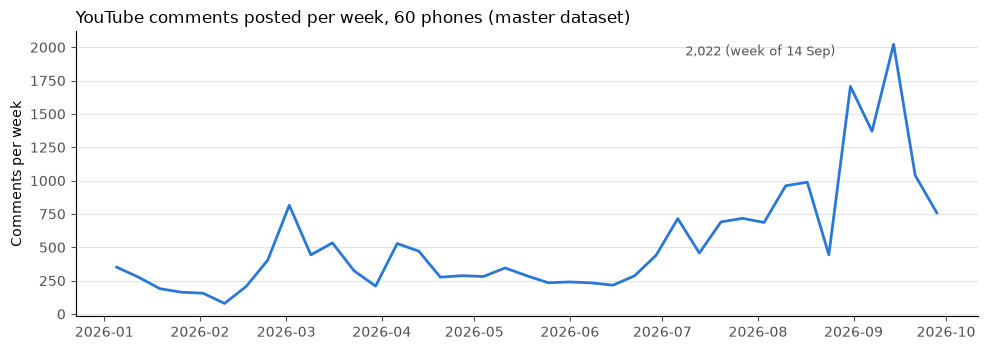

In [11]:
weekly = (master.assign(date=pd.to_datetime(master['date']))
                .resample('W-MON', on='date', label='left', closed='left')['comments_published'].sum())

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(weekly.index, weekly.values, color='#2a78d6', linewidth=2)
ax.set_title('YouTube comments posted per week, 60 phones (master dataset)', loc='left', fontsize=12)
ax.set_ylabel('Comments per week')
ax.grid(axis='y', color='#e4e3df', linewidth=0.8)
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(colors='#52514e')
peak = weekly.idxmax()
ax.annotate(f'{int(weekly.max()):,} (week of {peak:%d %b})', xy=(peak, weekly.max()), xytext=(-150, -8),
            textcoords='offset points', color='#52514e', fontsize=9)
fig.tight_layout()
fig.savefig(ROOT / 'docs' / 'figures' / 'scrum21_weekly_comments.png', dpi=150)
plt.show()

## 12. Limitations (say these if asked)

- **YouTube snapshot = one point in time.** `yt_*` values describe 2026-10-04, not each row's date. Do not use them as day-to-day features.
- **Activity counts come from a sample**: the top-ranked videos per phone and their top comments, not every upload on YouTube.
- **Trends values are relative to each phone's own peak (100)**, so compare shapes within a phone, not levels across phones.
- **`surge_label` is a one-day jump in search interest**, not a sales figure.
- **Flagged, not dropped**: 15 phones with weak Trends signal and 4 with a low YouTube on-target share.

**Rebuild and test:** `python src/build_master.py` · `python -m pytest tests/test_build_master.py`